In [1]:
import numpy as np
np.set_printoptions (suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [6]:
# Importer ce jeu de données avec la librairie pandas (c.f. read_csv)
ps2 = pd.read_csv('data/PS2.txt', sep=r'\s+', header=None)
fs1 = pd.read_csv('data/FS1.txt', sep=r'\s+', header=None)
profile = pd.read_csv('data/profile.txt', sep=r'\s+', header=None, names=['Cooler', 'Valve', 'Pump_leakage', 'Accumulator', 'Stable_flag'])

print('PS2     :', ps2.shape, '(cycles x mesures à 100 Hz)')
print('FS1     :', fs1.shape, '(cycles x mesures à 10 Hz)')
print('profile :', profile.shape)

PS2     : (2205, 6000) (cycles x mesures à 100 Hz)
FS1     : (2205, 600) (cycles x mesures à 10 Hz)
profile : (2205, 5)


In [7]:
# Transformer votre jeu de données issu de pandas qui sera de type Data Frame en numpy Exited Array(c.f. values)
type(ps2.values), type(fs1.values), type(profile.values)
ps2.shape, fs1.shape, profile.shape

((2205, 6000), (2205, 600), (2205, 5))

In [34]:
# l'initialisation de x les colonnes qui vont traités
X = ps2.iloc[:2000, :].values

# l'initialisation de y la colonne qui contient le résultat
Y = profile.iloc[:2000, 1].values

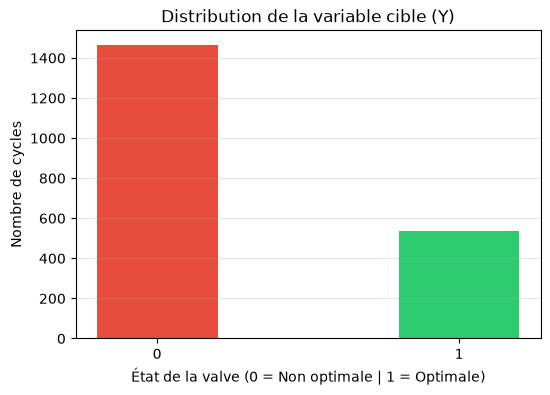

{np.int64(0): '73.2%', np.int64(1): '26.8%'}


In [36]:
Y_binaire = (profile.iloc[:2000, 0] == 100).astype(int).values

from collections import Counter
histogram = Counter(Y_binaire)

# 2. Affichage propre du nombre d'instances par classe
# Note : Une largeur (width) de 0.1 est trop fine pour des classes binaires (0 et 1). 
# On l'ajuste à 0.4 pour un rendu visuel net et professionnel.
plt.figure(figsize=(6, 4))
plt.bar(list(histogram.keys()), list(histogram.values()), width=0.4, color=['#e74c3c', '#2ecc71'])

plt.title("Distribution de la variable cible (Y)")
plt.xlabel("État de la valve (0 = Non optimale | 1 = Optimale)")
plt.ylabel("Nombre de cycles")
plt.xticks(list(histogram.keys())) # Force l'affichage des clés exactes sur l'axe X
plt.grid(axis='y', alpha=0.3)

plt.show()

print({k: f"{(v / sum(histogram.values())) * 100:.1f}%" for k, v in histogram.items()})

In [20]:
ep = np.sum(Y==1)/len(Y)
nep = np.sum(Y==0)/len(Y)

print('Excited : {0:.3f} et Non : {1:.3f}'.format(ep,nep))

Excited : 0.000 et Non : 0.000


In [12]:
from sklearn.model_selection import train_test_split

# Importation des algorithmes
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Importation des métriques (matrice de confusion, etc.)
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

# Importation des standards de normalisation
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [13]:
# La base de test contiendra 20 % des individus de la base totale
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.20, random_state=1)

print('Apprentissage :', Xtrain.shape, Ytrain.shape)
print('Test :', Xtest.shape, Ytest.shape)

Apprentissage : (1764, 9) (1764,)
Test : (441, 9) (441,)


In [14]:
DT = DecisionTreeClassifier(random_state=0, criterion='entropy')
DT.fit(Xtrain, Ytrain)

YDT = DT.predict(Xtest)

print('Performance Evaluation of Decision Tree')
print(confusion_matrix(Ytest, YDT))
print(classification_report(Ytest, YDT))

Performance Evaluation of Decision Tree
[[257  46]
 [ 34 104]]
              precision    recall  f1-score   support

           0       0.88      0.85      0.87       303
           1       0.69      0.75      0.72       138

    accuracy                           0.82       441
   macro avg       0.79      0.80      0.79       441
weighted avg       0.82      0.82      0.82       441



In [15]:
def evaluer_modele(nom, modele, Xtr, Xte, ytr, yte):
    modele.fit(Xtr, ytr)
    ypred = modele.predict(Xte)
    acc = accuracy_score(yte, ypred)
    rec = recall_score(yte, ypred)
    return {'Modèle': nom, 'Accuracy': acc, 'Recall': rec, 'Moyenne': (acc + rec) / 2}

def comparer_modeles(modeles, Xtr, Xte, ytr, yte):
    res = [evaluer_modele(n, m, Xtr, Xte, ytr, yte) for n, m in modeles.items()]
    return pd.DataFrame(res).sort_values('Moyenne', ascending=False).reset_index(drop=True)

In [16]:
def creer_modeles():
    return {
        'Arbre (entropy)': DecisionTreeClassifier(random_state=0, criterion='entropy'),
        'Arbre (gini)': DecisionTreeClassifier(random_state=0, criterion='gini'),
        'Arbre (entropy, max_depth=5)': DecisionTreeClassifier(random_state=0, criterion='entropy', max_depth=5),
        'Régression logistique': LogisticRegression(max_iter=1000),
    }

resultats_brut = comparer_modeles(creer_modeles(), Xtrain, Xtest, Ytrain, Ytest)
print('Résultats (NO normalisation) :')
resultats_brut

Résultats (NO normalisation) :


,Modèle,Accuracy,Recall,Moyenne
0,Arbre (gini),0.857143,0.833333,0.845238
1,"Arbre (entropy, max_depth=5)",0.818594,0.797101,0.807848
2,Arbre (entropy),0.818594,0.753623,0.786109
3,Régression logistique,0.811791,0.652174,0.731983
